# Assignment 2 — AgeDB Preparation
## Kaggle version for `nitingandhi/agedb-database`

This notebook is specifically adapted to the AgeDB dataset whose filenames follow:

`image_id_person_name_age_gender.jpg`

Example:

`10001_GoldieHawn_23_f.jpg`

### Output
- 200 identities
- 2 images per identity
- 400 images total
- `metadata.csv`
- ZIP containing the prepared dataset

This output is used by Notebook 2 for MTCNN + FaceNet verification and noise robustness experiments.

In [1]:
# 1. Imports and configuration

from pathlib import Path
import random
import shutil
import zipfile
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42
NUM_SUBJECTS = 200
IMAGES_PER_SUBJECT = 2
MAX_AGE_GAP = 9

random.seed(SEED)
np.random.seed(SEED)

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
OUTPUT_DIR = WORK_ROOT / "AgeDB_Assignment2"

print("Configuration ready.")

Configuration ready.


## 2. Find the AgeDB dataset automatically

Do **not** hard-code `/kaggle/input/datasets/...`.

Kaggle normally mounts the dataset under `/kaggle/input/...`, and the exact folder name can vary.

This cell searches for JPG files and identifies the dataset containing AgeDB-style filenames.

In [2]:
# 2. Locate AgeDB images

if not INPUT_ROOT.exists():
    raise FileNotFoundError("/kaggle/input was not found.")

all_jpgs = list(INPUT_ROOT.rglob("*.jpg")) + list(INPUT_ROOT.rglob("*.jpeg"))

print("Total JPG/JPEG files visible in Kaggle inputs:", len(all_jpgs))

if not all_jpgs:
    raise FileNotFoundError(
        "No JPG/JPEG files found. Make sure AgeDB_Database is added through "
        "Kaggle -> Add Input."
    )

# AgeDB filename pattern:
# numeric_id_name_age_gender.jpg
#
# Examples:
# 0_MariaCallas_35_f.jpg
# 10001_GoldieHawn_23_f.jpg
#
# Search for files matching that structure.
pattern = re.compile(
    r"^(\d+)_([^_]+(?:_[^_]+)*)_(\d+)_([mf])$",
    re.IGNORECASE
)

agedb_images = []

for p in all_jpgs:
    if pattern.match(p.stem):
        agedb_images.append(p)

print("AgeDB-style images found:", len(agedb_images))

if not agedb_images:
    raise ValueError(
        "No AgeDB-style filenames were detected. "
        "Check the dataset input and filename format."
    )

# Determine the mounted dataset directory from the first matching image.
DATASET_DIR = agedb_images[0].parents[
    len(agedb_images[0].parts) - len(INPUT_ROOT.parts) - 1
] if False else None

print("\nExample files:")
for p in agedb_images[:10]:
    print(" ", p)

Total JPG/JPEG files visible in Kaggle inputs: 16488
AgeDB-style images found: 16488

Example files:
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/7442_MickeyRooney_90_m.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/10042_HelenHunt_29_f.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/12179_GlendaJackson_67_f.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/12761_KathleenTurner_35_f.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/9557_RicardoMontalbаn_68_m.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/8071_JohnForsythe_46_m.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/1606_AlCorley_44_m.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/11047_JeanneMoreau_29_f.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/7336_LouisJourdan_24_m.jpg
  /kaggle/input/datasets/nitingandhi/agedb-database/AgeDB/8017_HenryFonda_33_m.jpg


## 3. Parse identity, age and gender

For this dataset:

`10001_GoldieHawn_23_f.jpg`

means:

- image ID = `10001`
- identity = `GoldieHawn`
- age = `23`
- gender = `f`

The identity is therefore obtained from the filename, not from a folder.

In [3]:
# 3. Parse filenames

records = []

for img_path in agedb_images:
    match = pattern.match(img_path.stem)

    if not match:
        continue

    image_id = int(match.group(1))
    identity = match.group(2)
    age = int(match.group(3))
    gender = match.group(4).lower()

    records.append({
        "path": str(img_path),
        "filename": img_path.name,
        "image_id": image_id,
        "identity": identity,
        "age": age,
        "gender": gender,
    })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No images were successfully parsed.")

print("Parsed images:", len(df))
print("Unique identities:", df["identity"].nunique())

display(df.head(10))

Parsed images: 16488
Unique identities: 567


,path,filename,image_id,identity,age,gender
0,/kaggle/input/datasets/nitingandhi/agedb-datab...,7442_MickeyRooney_90_m.jpg,7442,MickeyRooney,90,m
1,/kaggle/input/datasets/nitingandhi/agedb-datab...,10042_HelenHunt_29_f.jpg,10042,HelenHunt,29,f
2,/kaggle/input/datasets/nitingandhi/agedb-datab...,12179_GlendaJackson_67_f.jpg,12179,GlendaJackson,67,f
3,/kaggle/input/datasets/nitingandhi/agedb-datab...,12761_KathleenTurner_35_f.jpg,12761,KathleenTurner,35,f
4,/kaggle/input/datasets/nitingandhi/agedb-datab...,9557_RicardoMontalbаn_68_m.jpg,9557,RicardoMontalbаn,68,m
5,/kaggle/input/datasets/nitingandhi/agedb-datab...,8071_JohnForsythe_46_m.jpg,8071,JohnForsythe,46,m
6,/kaggle/input/datasets/nitingandhi/agedb-datab...,1606_AlCorley_44_m.jpg,1606,AlCorley,44,m
7,/kaggle/input/datasets/nitingandhi/agedb-datab...,11047_JeanneMoreau_29_f.jpg,11047,JeanneMoreau,29,f
8,/kaggle/input/datasets/nitingandhi/agedb-datab...,7336_LouisJourdan_24_m.jpg,7336,LouisJourdan,24,m
9,/kaggle/input/datasets/nitingandhi/agedb-datab...,8017_HenryFonda_33_m.jpg,8017,HenryFonda,33,m


In [4]:
# 4. Inspect the dataset

print("=" * 60)
print("AGEDB SUMMARY")
print("=" * 60)

print("Images:", len(df))
print("Identities:", df["identity"].nunique())

print("\nGender:")
display(df["gender"].value_counts().rename_axis("gender").to_frame("images"))

print("\nAge:")
display(df["age"].describe().round(2))

images_per_identity = df.groupby("identity").size()

print("\nImages per identity:")
display(images_per_identity.describe().round(2))

print(
    "\nIdentities with at least 2 images:",
    int((images_per_identity >= 2).sum())
)

AGEDB SUMMARY
Images: 16488
Identities: 567

Gender:


,images
gender,
m,9788
f,6700



Age:


count    16488.00
mean        46.26
std         17.44
min          1.00
25%         32.00
50%         44.00
75%         59.00
max        101.00
Name: age, dtype: float64


Images per identity:


count    567.00
mean      29.08
std        9.50
min        1.00
25%       23.00
50%       29.00
75%       35.00
max       78.00
dtype: float64


Identities with at least 2 images: 566


## 5. Select 200 identities and two images per identity

For each identity, we choose two images.

We prefer pairs whose age difference is at most 9 years. If an identity has no such pair, it is skipped when enough other identities are available.

This keeps the selected dataset controlled and reproducible.

In [5]:
# 5. Select a pair for every identity

def choose_pair(group, max_age_gap=MAX_AGE_GAP):
    group = group.sort_values(["age", "image_id"]).reset_index(drop=True)

    if len(group) < 2:
        return None

    possible = []

    for i in range(len(group)):
        for j in range(i + 1, len(group)):
            gap = abs(int(group.loc[i, "age"]) - int(group.loc[j, "age"]))

            if gap <= max_age_gap:
                possible.append((gap, i, j))

    if not possible:
        return None

    # Prefer the largest valid age gap so the pair contains
    # meaningful within-identity variation while staying controlled.
    gap, i, j = max(
        possible,
        key=lambda x: (x[0], -x[1], -x[2])
    )

    a = group.loc[i]
    b = group.loc[j]

    return {
        "identity": group.loc[0, "identity"],
        "image1": a["path"],
        "image2": b["path"],
        "age1": int(a["age"]),
        "age2": int(b["age"]),
        "gender": a["gender"],
        "age_gap": int(gap),
    }


pairs = []

for identity, group in df.groupby("identity", sort=True):
    result = choose_pair(group)

    if result is not None:
        pairs.append(result)

pairs_df = pd.DataFrame(pairs)

print("Identities with a valid pair:", len(pairs_df))

if len(pairs_df) < NUM_SUBJECTS:
    raise ValueError(
        f"Only {len(pairs_df)} identities have a valid pair with age gap "
        f"<= {MAX_AGE_GAP}. Need {NUM_SUBJECTS}."
    )

print("Maximum selected age gap:", pairs_df["age_gap"].max())

Identities with a valid pair: 566
Maximum selected age gap: 9


In [6]:
# 6. Deterministically select 200 identities

selected = pairs_df.sample(
    n=NUM_SUBJECTS,
    random_state=SEED
).sort_values("identity").reset_index(drop=True)

selected.insert(
    0,
    "subject_id",
    [f"subject_{i:03d}" for i in range(1, NUM_SUBJECTS + 1)]
)

print("Selected identities:", len(selected))
print("Images after selection:", len(selected) * IMAGES_PER_SUBJECT)

display(selected.head(10))

Selected identities: 200
Images after selection: 400


,subject_id,identity,image1,image2,age1,age2,gender,age_gap
0,subject_001,AbeVigoda,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,49,58,m,9
1,subject_002,AlCorley,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,20,29,m,9
2,subject_003,AlanRickman,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,30,39,m,9
3,subject_004,AlbertSchweitzer,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,58,67,m,9
4,subject_005,AlbertoSordi,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,18,27,m,9
5,subject_006,AlecGuinness,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,26,35,m,9
6,subject_007,AliMacGraw,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,25,34,f,9
7,subject_008,AmandaRedman,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,22,31,f,9
8,subject_009,AndreMarieAmpКre,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,30,38,m,8
9,subject_010,AngelaLansbury,/kaggle/input/datasets/nitingandhi/agedb-datab...,/kaggle/input/datasets/nitingandhi/agedb-datab...,19,28,f,9


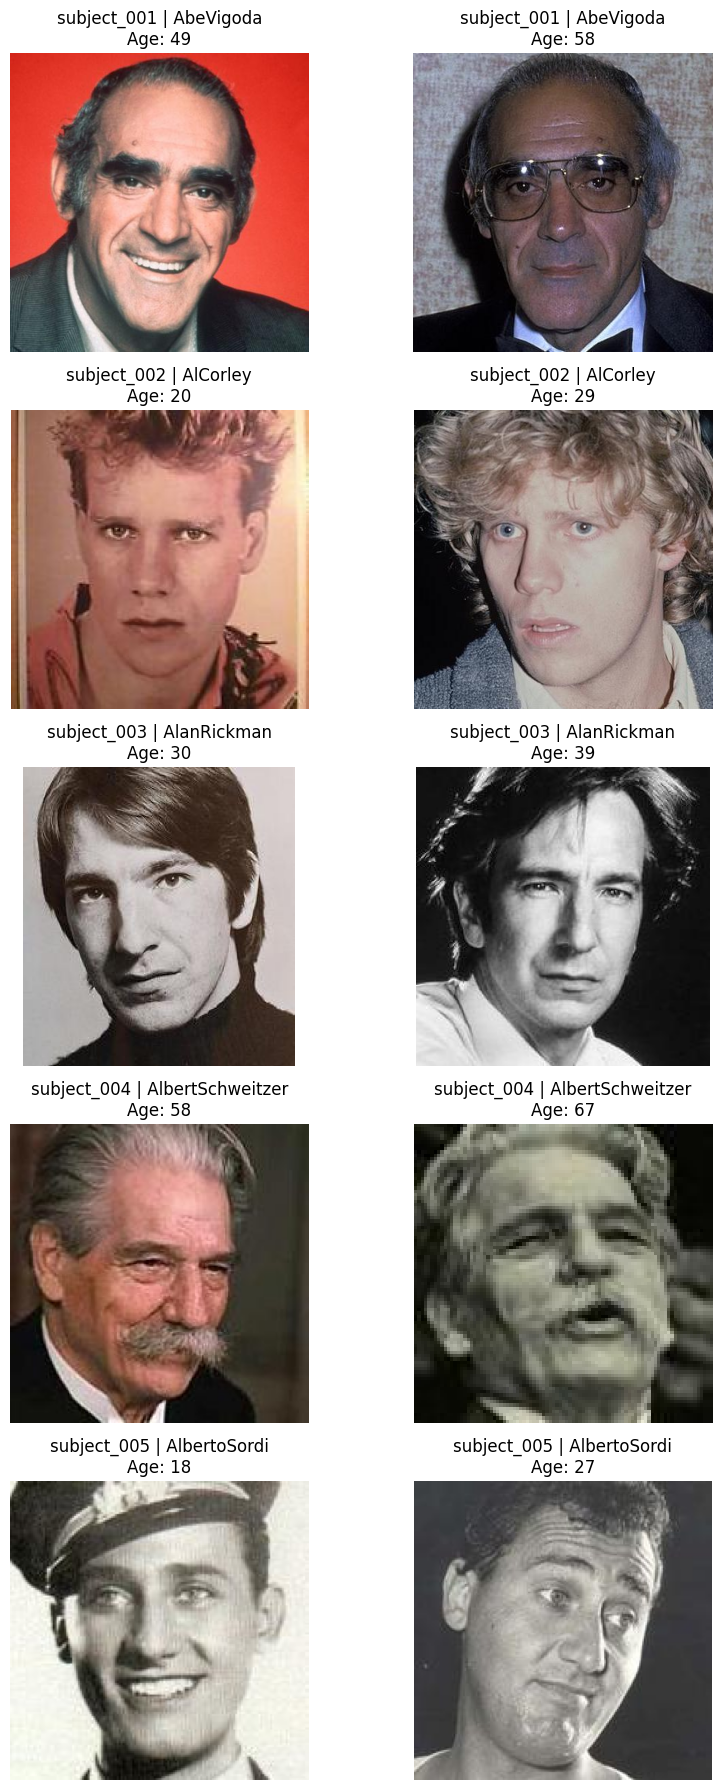

In [7]:
# 7. Visualize a few selected genuine pairs

sample = selected.head(5)

fig, axes = plt.subplots(5, 2, figsize=(9, 18))

for r, (_, row) in enumerate(sample.iterrows()):
    img1 = Image.open(row["image1"]).convert("RGB")
    img2 = Image.open(row["image2"]).convert("RGB")

    axes[r, 0].imshow(img1)
    axes[r, 0].set_title(
        f'{row["subject_id"]} | {row["identity"]}\n'
        f'Age: {row["age1"]}'
    )
    axes[r, 0].axis("off")

    axes[r, 1].imshow(img2)
    axes[r, 1].set_title(
        f'{row["subject_id"]} | {row["identity"]}\n'
        f'Age: {row["age2"]}'
    )
    axes[r, 1].axis("off")

plt.tight_layout()
plt.show()

## 6. Create the clean 200-subject dataset

The resulting structure is:

```text
AgeDB_Assignment2/
├── subject_001/
│   ├── subject_001_img1.jpg
│   └── subject_001_img2.jpg
├── subject_002/
│   ├── subject_002_img1.jpg
│   └── subject_002_img2.jpg
...
└── metadata.csv
```

In [8]:
# 8. Create output directory

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

final_records = []

for _, row in selected.iterrows():
    sid = row["subject_id"]
    subject_dir = OUTPUT_DIR / sid
    subject_dir.mkdir(parents=True, exist_ok=True)

    for image_number, source_col, age_col in [
        (1, "image1", "age1"),
        (2, "image2", "age2"),
    ]:
        source = Path(row[source_col])

        destination = (
            subject_dir /
            f"{sid}_img{image_number}{source.suffix.lower()}"
        )

        shutil.copy2(source, destination)

        final_records.append({
            "subject_id": sid,
            "image_number": image_number,
            "identity": row["identity"],
            "age": int(row[age_col]),
            "gender": row["gender"],
            "age_gap": int(row["age_gap"]),
            "source_filename": source.name,
            "new_path": str(destination),
        })

metadata = pd.DataFrame(final_records)

metadata_path = OUTPUT_DIR / "metadata.csv"
metadata.to_csv(metadata_path, index=False)

print("Created:", len(metadata), "images")
print("Subjects:", metadata["subject_id"].nunique())
print("Metadata:", metadata_path)

display(metadata.head(10))

Created: 400 images
Subjects: 200
Metadata: /kaggle/working/AgeDB_Assignment2/metadata.csv


,subject_id,image_number,identity,age,gender,age_gap,source_filename,new_path
0,subject_001,1,AbeVigoda,49,m,9,2325_AbeVigoda_49_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_001/...
1,subject_001,2,AbeVigoda,58,m,9,2333_AbeVigoda_58_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_001/...
2,subject_002,1,AlCorley,20,m,9,1592_AlCorley_20_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_002/...
3,subject_002,2,AlCorley,29,m,9,1600_AlCorley_29_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_002/...
4,subject_003,1,AlanRickman,30,m,9,3006_AlanRickman_30_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_003/...
5,subject_003,2,AlanRickman,39,m,9,3011_AlanRickman_39_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_003/...
6,subject_004,1,AlbertSchweitzer,58,m,9,1167_AlbertSchweitzer_58_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_004/...
7,subject_004,2,AlbertSchweitzer,67,m,9,1176_AlbertSchweitzer_67_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_004/...
8,subject_005,1,AlbertoSordi,18,m,9,7743_AlbertoSordi_18_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_005/...
9,subject_005,2,AlbertoSordi,27,m,9,7746_AlbertoSordi_27_m.jpg,/kaggle/working/AgeDB_Assignment2/subject_005/...


In [9]:
# 9. Final validation

subject_counts = metadata.groupby("subject_id").size()

print("=" * 65)
print("FINAL DATASET VALIDATION")
print("=" * 65)

print("Subjects:", len(subject_counts))
print("Images:", len(metadata))
print("Images per subject:", sorted(subject_counts.unique()))
print("Age range:", metadata["age"].min(), "-", metadata["age"].max())
print("Mean age:", round(metadata["age"].mean(), 2))
print(
    "Mean age gap:",
    round(metadata.groupby("subject_id")["age_gap"].first().mean(), 2)
)
print(
    "Maximum age gap:",
    int(metadata.groupby("subject_id")["age_gap"].first().max())
)

missing_files = [
    p for p in metadata["new_path"]
    if not Path(p).exists()
]

print("Missing generated files:", len(missing_files))

assert len(subject_counts) == NUM_SUBJECTS
assert subject_counts.eq(IMAGES_PER_SUBJECT).all()
assert len(metadata) == NUM_SUBJECTS * IMAGES_PER_SUBJECT
assert len(missing_files) == 0

print("\n✓ ALL VALIDATION CHECKS PASSED")

FINAL DATASET VALIDATION
Subjects: 200
Images: 400
Images per subject: [np.int64(2)]
Age range: 4 - 82
Mean age: 31.0
Mean age gap: 8.94
Maximum age gap: 9
Missing generated files: 0

✓ ALL VALIDATION CHECKS PASSED


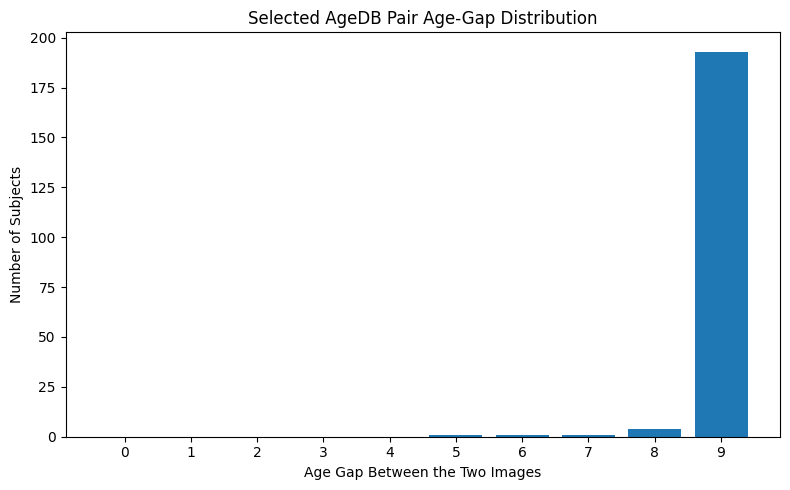

In [10]:
# 10. Age-gap distribution

plt.figure(figsize=(8, 5))
plt.hist(
    metadata.groupby("subject_id")["age_gap"].first(),
    bins=np.arange(0, MAX_AGE_GAP + 2) - 0.5,
    rwidth=0.8
)
plt.xlabel("Age Gap Between the Two Images")
plt.ylabel("Number of Subjects")
plt.title("Selected AgeDB Pair Age-Gap Distribution")
plt.xticks(range(MAX_AGE_GAP + 1))
plt.tight_layout()
plt.show()

,subjects
gender,
m,114
f,86


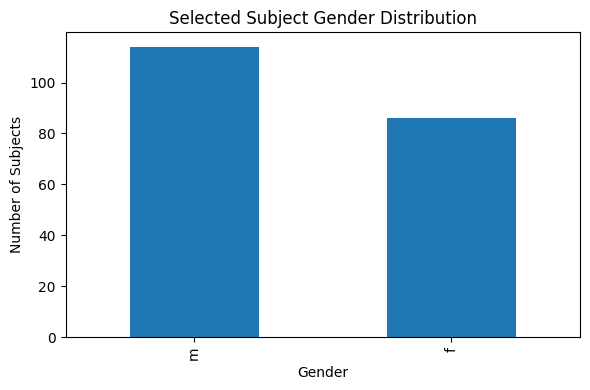

In [11]:
# 11. Gender distribution of selected subjects

subject_gender = (
    metadata.groupby("subject_id")["gender"]
    .first()
    .value_counts()
)

display(
    subject_gender
    .rename_axis("gender")
    .to_frame("subjects")
)

plt.figure(figsize=(6, 4))
subject_gender.plot(kind="bar")
plt.xlabel("Gender")
plt.ylabel("Number of Subjects")
plt.title("Selected Subject Gender Distribution")
plt.tight_layout()
plt.show()

In [12]:
# 12. Create ZIP for Notebook 2

zip_base = WORK_ROOT / "AgeDB_Assignment2_Prepared"

zip_path = Path(
    shutil.make_archive(
        str(zip_base),
        "zip",
        root_dir=WORK_ROOT,
        base_dir=OUTPUT_DIR.name
    )
)

print("ZIP created:")
print(zip_path)

print("ZIP size (MB):", round(zip_path.stat().st_size / (1024**2), 2))

with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()

print("Number of files in ZIP:", len(names))
print("\nFirst files:")

for name in names[:20]:
    print(" ", name)

print("\n✓ Notebook 1 complete.")
print("Use this ZIP/output as the input for Notebook 2.")

ZIP created:
/kaggle/working/AgeDB_Assignment2_Prepared.zip
ZIP size (MB): 3.49
Number of files in ZIP: 602

First files:
  AgeDB_Assignment2/
  AgeDB_Assignment2/subject_001/
  AgeDB_Assignment2/subject_002/
  AgeDB_Assignment2/subject_003/
  AgeDB_Assignment2/subject_004/
  AgeDB_Assignment2/subject_005/
  AgeDB_Assignment2/subject_006/
  AgeDB_Assignment2/subject_007/
  AgeDB_Assignment2/subject_008/
  AgeDB_Assignment2/subject_009/
  AgeDB_Assignment2/subject_010/
  AgeDB_Assignment2/subject_011/
  AgeDB_Assignment2/subject_012/
  AgeDB_Assignment2/subject_013/
  AgeDB_Assignment2/subject_014/
  AgeDB_Assignment2/subject_015/
  AgeDB_Assignment2/subject_016/
  AgeDB_Assignment2/subject_017/
  AgeDB_Assignment2/subject_018/
  AgeDB_Assignment2/subject_019/

✓ Notebook 1 complete.
Use this ZIP/output as the input for Notebook 2.


# Notebook 1 complete

### Expected result

```text
200 subjects
×
2 images
=
400 images
```

The important output files are:

- `AgeDB_Assignment2/metadata.csv`
- `AgeDB_Assignment2_Prepared.zip`

Notebook 2 should use the prepared dataset rather than re-selecting identities.